# Sea-level anomalies

**Indicator:** detrended sea-level anomalies by storm year and by month at the tide gauge, period-mean anomaly maps over the EEZ, and their relationship with ENSO.

```{glue:figure} SL_MMA_annual_station
:scale: 40%
:align: right
```

Sea-level anomalies are departures from the long-term trend and the mean seasonal cycle. In the western tropical Pacific they are dominated by ENSO: trade-wind changes during El Niño lower sea level by tens of centimetres for months, whereas La Niña raises it. Years are grouped into **storm years** (May–April, labelled by the starting year), matching the convention used for flooding.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from myst_nb import glue

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level.py).')
sys.path.insert(0, str(repo_root / 'functions'))

from data_downloaders import download_oni_index, download_uhslc_data
from sea_level import (
    COMPLETENESS_THRESHOLD, ONI_URL, annual_completeness, build_output_filename, build_site_tag,
    detect_enso_events, eez_bounds_360, load_site_config, monthly_mean_with_completeness,
    process_trend_with_nan, resolve_eez, save_dict_json, save_table_to_csv, sea_level_config_path,
    station_series, storm_year,
)
from sea_level_plotting import plot_sl_anomaly_period_maps, plot_station_anomaly_series

## 1. Configuration

In [3]:
site_key = 'Palau'  # sea-level configuration written by 00_sea_level_setup.ipynb
site_cfg = load_site_config(sea_level_config_path(repo_root, site_key))

country = site_cfg['country']
uhslc_id = int(site_cfg['selected_uhslc_id'])
station = site_cfg['station']
station_lon, station_lat = float(site_cfg['station_lon']), float(site_cfg['station_lat'])
start_date = pd.Timestamp(site_cfg['start_date'])
end_date = pd.Timestamp(site_cfg['end_date'])
sea_level_dir = repo_root / site_cfg['sea_level_data_dir']
eez, eez_geometry = resolve_eez(country, repo_root / site_cfg['eez_file'])

site_name = site_cfg['site_name']
site_tag = build_site_tag(site_name, station_lon, station_lat)
fig_dir = repo_root / 'outputs' / 'figures' / site_tag
tab_dir = repo_root / 'outputs' / 'tables' / site_tag
matrix_dir = repo_root / 'matrix_cc' / 'figures'
for directory in (fig_dir, tab_dir, matrix_dir):
    directory.mkdir(parents=True, exist_ok=True)

def out(name, ext='png'):
    return build_output_filename(name, site_name, station_lon, station_lat, ext=ext)

glue('station', station, display=False)
glue('country', country, display=False)
print(f'{station}, {country} (UHSLC {uhslc_id:03d}); analysis period {start_date:%Y-%m-%d} to {end_date:%Y-%m-%d}')
print(f'Outputs: {fig_dir.relative_to(repo_root)} and {tab_dir.relative_to(repo_root)}')

Malakal, Palau (UHSLC 007); analysis period 1993-01-01 to 2024-12-31
Outputs: outputs/figures/palau_uhslc007_lat7p329_lon134p450 and outputs/tables/palau_uhslc007_lat7p329_lon134p450


## 2. Tide-gauge anomalies

1. Daily sea level (m) over the analysis period, with the linear trend removed.
2. Monthly means are kept only when at least 75% of days are present.
3. The mean seasonal cycle (monthly climatology) is removed to obtain monthly anomalies.
4. Storm-year mean, minimum and maximum are computed from the daily anomalies; years with less than 75% daily coverage are left missing.

In [4]:
rsl = download_uhslc_data(sea_level_dir, uhslc_id, 'daily')
daily = (station_series(rsl) / 1000.0).sel(time=slice(start_date, end_date))
_, trend_line, trend_rate, _, _ = process_trend_with_nan(daily)
detrended = daily - trend_line

monthly = monthly_mean_with_completeness(detrended, COMPLETENESS_THRESHOLD)
climatology = monthly.groupby(monthly.index.month).mean()
monthly_anomaly = monthly - climatology.reindex(monthly.index.month).values

daily_anomaly = detrended.to_series() - climatology.reindex(detrended.to_series().index.month).values
completeness = annual_completeness(detrended, by='storm')
labels = storm_year(daily_anomaly.index)
yearly = daily_anomaly.groupby(labels).agg(['mean', 'min', 'max'])
yearly.index.name = 'storm_year'
yearly['completeness'] = completeness.reindex(yearly.index)
yearly.loc[yearly['completeness'] < COMPLETENESS_THRESHOLD, ['mean', 'min', 'max']] = np.nan
print(f'Removed trend: {1000 * float(trend_rate):.2f} mm/yr. '
      f'Valid storm years: {int(yearly["mean"].notna().sum())} of {len(yearly)}.')
yearly.round(3).T

Removed trend: 4.37 mm/yr. Valid storm years: 31 of 33.


storm_year,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mean,NaN,-0.081,-0.085,0.017,-0.049,-0.154,0.185,0.131,0.103,0.044,...,-0.210,0.074,0.010,-0.159,-0.049,0.031,0.047,0.012,-0.084,NaN
min,NaN,-0.186,-0.202,-0.140,-0.230,-0.261,0.047,-0.039,-0.030,-0.087,...,-0.326,-0.088,-0.104,-0.274,-0.166,-0.115,-0.062,-0.145,-0.199,NaN
max,NaN,0.013,0.087,0.267,0.133,0.147,0.332,0.285,0.304,0.312,...,0.072,0.221,0.237,-0.049,0.069,0.271,0.203,0.122,0.118,NaN
completeness,0.329,1.000,0.967,1.000,1.000,1.000,1.000,0.989,1.000,1.000,...,1.000,0.918,1.000,0.989,0.981,1.000,1.000,1.000,0.986,0.658


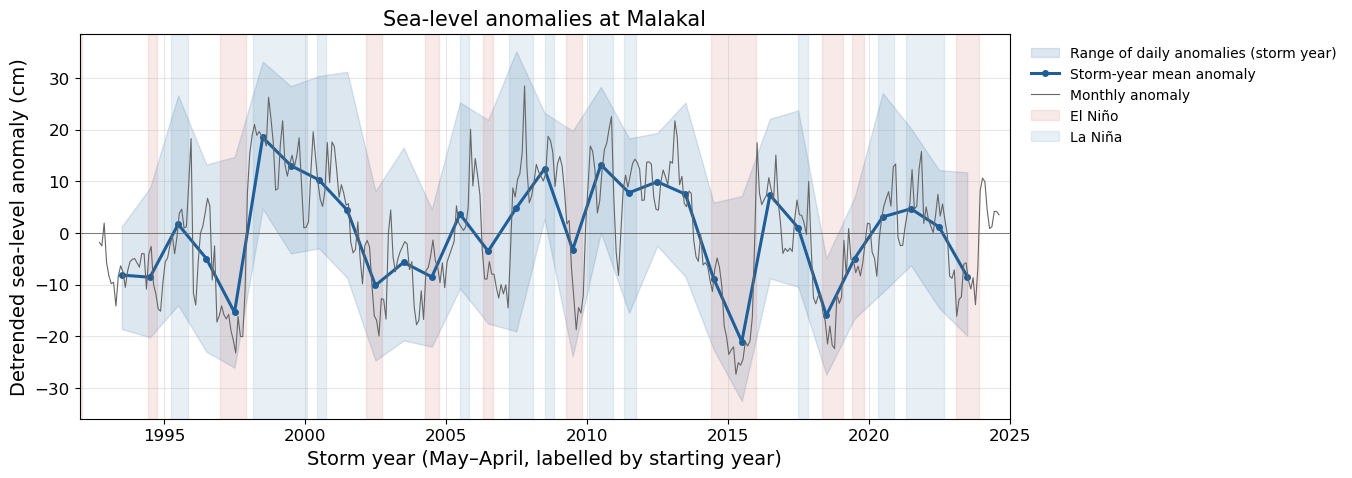

In [5]:
oni = download_oni_index(ONI_URL)
enso_events = detect_enso_events(oni)
enso_events = enso_events[(enso_events.index >= start_date - pd.DateOffset(months=12)) & (enso_events.index <= end_date)]

fig, ax = plot_station_anomaly_series(yearly, monthly_anomaly, enso_events, station)
glue('SL_MMA_annual_station', fig, display=False)
fig.savefig(fig_dir / out('SL_anomaly_station_timeseries'), dpi=300, bbox_inches='tight')

```{glue:figure} SL_MMA_annual_station
:name: "SL_MMA_annual_station"

Storm-year mean (line) and range (shading) of detrended, de-seasoned daily sea level at the {glue:text}`station` tide gauge, with monthly anomalies (grey). El Niño and La Niña periods follow the ONI ±0.5 °C threshold sustained for at least five months.
```

## 3. Period-mean anomaly maps over the EEZ

Monthly altimetry is detrended at every grid cell over the full analysis period; maps show the mean anomaly for groups of storm years. The circle shows the tide-gauge anomaly for the same months on the same colour scale.

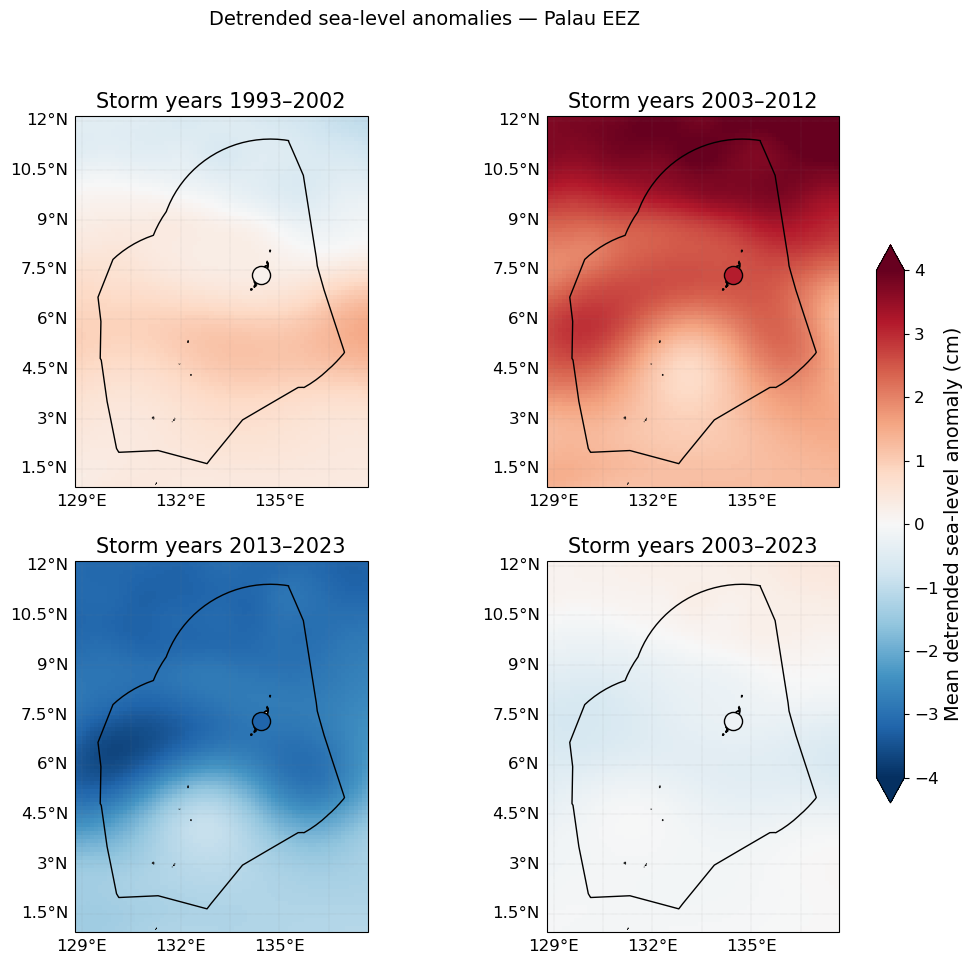

In [6]:
cmems_path = repo_root / site_cfg['cmems_file']
west, east, south, north = site_cfg['cmems_bounds']
ds = xr.open_dataset(cmems_path, chunks={'time': 366})
ds = ds.assign_coords(longitude=ds.longitude % 360).sortby('longitude')
sla_monthly = (ds['sla'].sel(time=slice(start_date, end_date), longitude=slice(west, east), latitude=slice(south, north))
               .resample(time='MS').mean().load())
_, sla_trend_line, _, _, _ = process_trend_with_nan(sla_monthly)
sla_detrended = sla_monthly - sla_trend_line

# last storm year whose April ends inside the analysis period
last_storm_year = end_date.year - 1 if end_date >= pd.Timestamp(f'{end_date.year}-04-30') else end_date.year - 2
periods = []
for y0, y1 in [(1993, 2002), (2003, 2012), (2013, last_storm_year), (2003, last_storm_year)]:
    periods.append((f'Storm years {y0}–{y1}', f'{y0}-05-01', f'{y1 + 1}-04-30'))

w_, e_, s_, n_ = eez_bounds_360(eez_geometry)
fig, axes = plot_sl_anomaly_period_maps(
    sla_detrended, periods, eez, (w_ - 0.7, e_ + 0.7), (s_ - 0.7, n_ + 0.7),
    station=(station_lon, station_lat), station_anomaly_m=monthly_anomaly,
    title=f'Detrended sea-level anomalies — {country} EEZ',
)
glue('SL_YMA_decadal', fig, display=False)
fig.savefig(fig_dir / out('SL_anomaly_period_maps'), dpi=300, bbox_inches='tight')

```{glue:figure} SL_YMA_decadal
:name: "SL_YMA_decadal"

Mean detrended sea-level anomaly for groups of storm years over the {glue:text}`country` EEZ (shading) and at the {glue:text}`station` tide gauge (circle). Because the trend is removed over the full period, the maps highlight decadal variability rather than the long-term rise.
```

## 4. Summary table and saved outputs

In [7]:
yearly_out = (100 * yearly[['mean', 'min', 'max']]).round(2).rename(columns=lambda c: f'{c}_anomaly_cm')
yearly_out['completeness'] = yearly['completeness'].round(3)
yearly_out = yearly_out.reset_index()
save_table_to_csv(yearly_out, tab_dir, out('SL_anomaly_yearly_mean', 'csv'))

monthly_out = (100 * monthly_anomaly).round(2).rename('anomaly_cm').rename_axis('month').reset_index()
save_table_to_csv(monthly_out, tab_dir, out('SL_anomaly_monthly_series', 'csv'))

valid = yearly.dropna(subset=['mean'])
anomaly_metrics = {
    'station': station,
    'uhslc_id': uhslc_id,
    'period_start': f'{start_date:%Y-%m-%d}',
    'period_end': f'{end_date:%Y-%m-%d}',
    'removed_trend_mm_yr': 1000 * float(trend_rate),
    'valid_storm_years': int(len(valid)),
    'highest_storm_year': int(valid['mean'].idxmax()),
    'highest_storm_year_anomaly_cm': 100 * float(valid['mean'].max()),
    'lowest_storm_year': int(valid['mean'].idxmin()),
    'lowest_storm_year_anomaly_cm': 100 * float(valid['mean'].min()),
    'monthly_anomaly_std_cm': 100 * float(monthly_anomaly.std()),
}
save_dict_json(anomaly_metrics, tab_dir, out('SL_anomaly_summary_metrics', 'json'))
pd.Series(anomaly_metrics).to_frame('value')

,value
station,Malakal
uhslc_id,7
period_start,1993-01-01
period_end,2024-12-31
removed_trend_mm_yr,4.373151
valid_storm_years,31
highest_storm_year,1998
highest_storm_year_anomaly_cm,18.546894
lowest_storm_year,2015
lowest_storm_year_anomaly_cm,-21.012539


## Interpretation and reproducibility notes

- Anomalies are relative to the linear trend and mean seasonal cycle over the analysis period at the gauge; changing the period changes both.
- Storm years run from May to April and are labelled by their first year (e.g. 1997 = May 1997–April 1998, the 1997–98 El Niño).
- Years and months below 75% data completeness are left missing rather than filled.
- Maps use monthly altimetry detrended cell by cell; the tide-gauge circle uses the same months and colour scale but is a point measurement.